# Initial Findings
- Initial Findings of US Accidents from 2013-2026
- All Findings before Cleaning of Dataset
- Goal: present initial findings relating to our statement question

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries importated successfully!")

Libraries importated successfully!


In [22]:
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
BLUE, ORANGE, GRAY, LIGHT = "#2a78d6", "#eb6834", "#52514e", "#b4b2a9"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": GRAY, "xtick.color": GRAY,
    "ytick.color": GRAY, "axes.grid": True, "grid.color": "#ecebe7",
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
})

## Loading Data

In [23]:
raw = pd.read_csv('/Users/paolohalog/Desktop/Need4Data26/US_Accidents_March23_sampled_500k.csv')
df = raw.copy()
df.head(5)

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,Zipcode,Country,Timezone,Airport_Code,Weather_Timestamp,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-2047758,Source2,2,2019-06-12 10:10:56,2019-06-12 10:55:58,30.641211,-91.153481,NaN,NaN,0.000,Accident on LA-19 Baker-Zachary Hwy at Lower Z...,Highway 19,Zachary,East Baton Rouge,LA,70791-4610,US,US/Central,KBTR,2019-06-12 09:53:00,77.0,77.0,62.0,29.92,10.0,NW,5.0,0.0,Fair,False,False,False,False,False,False,False,False,False,False,False,True,False,Day,Day,Day,Day
1,A-4694324,Source1,2,2022-12-03 23:37:14.000000000,2022-12-04 01:56:53.000000000,38.990562,-77.399070,38.990037,-77.398282,0.056,Incident on FOREST RIDGE DR near PEPPERIDGE PL...,Forest Ridge Dr,Sterling,Loudoun,VA,20164-2813,US,US/Eastern,KIAD,2022-12-03 23:52:00,45.0,43.0,48.0,29.91,10.0,W,5.0,0.0,Fair,False,False,False,False,False,False,False,False,False,False,False,False,False,Night,Night,Night,Night
2,A-5006183,Source1,2,2022-08-20 13:13:00.000000000,2022-08-20 15:22:45.000000000,34.661189,-120.492822,34.661189,-120.492442,0.022,Accident on W Central Ave from Floradale Ave t...,Floradale Ave,Lompoc,Santa Barbara,CA,93436,US,US/Pacific,KLPC,2022-08-20 12:56:00,68.0,68.0,73.0,29.79,10.0,W,13.0,0.0,Fair,False,False,False,False,False,False,False,False,False,False,False,True,False,Day,Day,Day,Day
3,A-4237356,Source1,2,2022-02-21 17:43:04,2022-02-21 19:43:23,43.680592,-92.993317,43.680574,-92.972223,1.054,Incident on I-90 EB near REST AREA Drive with ...,14th St NW,Austin,Mower,MN,55912,US,US/Central,KAUM,2022-02-21 17:35:00,27.0,15.0,86.0,28.49,10.0,ENE,15.0,0.0,Wintry Mix,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
4,A-6690583,Source1,2,2020-12-04 01:46:00,2020-12-04 04:13:09,35.395484,-118.985176,35.395476,-118.985995,0.046,RP ADV THEY LOCATED SUSP VEH OF 20002 - 726 CR...,River Blvd,Bakersfield,Kern,CA,93305-2649,US,US/Pacific,KBFL,2020-12-04 01:54:00,42.0,42.0,34.0,29.77,10.0,CALM,0.0,0.0,Fair,False,False,False,False,False,False,False,False,False,False,False,False,False,Night,Night,Night,Night


## Shape and Data Types
Displays how big the data is, data types within the data, etc

In [24]:
df.shape
# 500,000 rows and 46 columns

(500000, 46)

In [25]:
df.describe()

,Severity,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in)
count,500000.000000,500000.000000,500000.000000,279623.000000,279623.000000,500000.000000,489534.000000,370983.000000,488870.000000,491072.000000,488709.000000,463013.000000,357384.000000
mean,2.212748,36.206421,-94.736583,36.273192,-95.776553,0.564317,61.646254,58.229028,64.834921,29.536621,9.091540,7.681347,0.008289
std,0.486661,5.071411,17.405761,5.265333,18.120211,1.774872,19.000133,22.352246,22.826158,1.008666,2.708083,5.431361,0.101865
min,1.000000,24.562117,-124.497420,24.570110,-124.497419,0.000000,-77.800000,-53.200000,1.000000,0.120000,0.000000,0.000000,0.000000
25%,2.000000,33.416823,-117.233047,33.474773,-117.778324,0.000000,49.000000,43.000000,48.000000,29.370000,10.000000,4.600000,0.000000
50%,2.000000,35.832147,-87.794365,36.192669,-88.039013,0.029000,64.000000,62.000000,67.000000,29.860000,10.000000,7.000000,0.000000
75%,2.000000,40.082443,-80.359601,40.181341,-80.252449,0.465000,76.000000,75.000000,84.000000,30.030000,10.000000,10.400000,0.000000
max,4.000000,48.999569,-67.484130,48.998901,-67.484130,193.479996,207.000000,207.000000,100.000000,38.440000,130.000000,822.800000,10.130000


In [26]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "unique": df.nunique(),
    "example": df.iloc[0],
})
overview

# note high percentage of Null Values held in End_Lat and End_Lng columns
# may not need for analysis

,dtype,non_null,missing_%,unique,example
ID,str,500000,0.0,500000,A-2047758
Source,str,500000,0.0,3,Source2
Severity,int64,500000,0.0,4,2
Start_Time,str,500000,0.0,487027,2019-06-12 10:10:56
End_Time,str,500000,0.0,493821,2019-06-12 10:55:58
Start_Lat,float64,500000,0.0,368965,30.641211
Start_Lng,float64,500000,0.0,370195,-91.153481
End_Lat,float64,279623,44.1,220333,NaN
End_Lng,float64,279623,44.1,221463,NaN
Distance(mi),float64,500000,0.0,10627,0.0


In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 46 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     500000 non-null  str    
 1   Source                 500000 non-null  str    
 2   Severity               500000 non-null  int64  
 3   Start_Time             500000 non-null  str    
 4   End_Time               500000 non-null  str    
 5   Start_Lat              500000 non-null  float64
 6   Start_Lng              500000 non-null  float64
 7   End_Lat                279623 non-null  float64
 8   End_Lng                279623 non-null  float64
 9   Distance(mi)           500000 non-null  float64
 10  Description            499999 non-null  str    
 11  Street                 499309 non-null  str    
 12  City                   499981 non-null  str    
 13  County                 500000 non-null  str    
 14  State                  500000 non-null  str    

In [28]:
df.dtypes.value_counts()

str        20
bool       13
float64    12
int64       1
Name: count, dtype: int64

## Missing Values and Duplicate Values

In [29]:
print("Duplicate rows:", df.duplicated().sum(), "| Duplicate IDs:", df["ID"].duplicated().sum())
# ensures no values are duplicated in the ID column, which is a unique identifier for each row

Duplicate rows: 0 | Duplicate IDs: 0


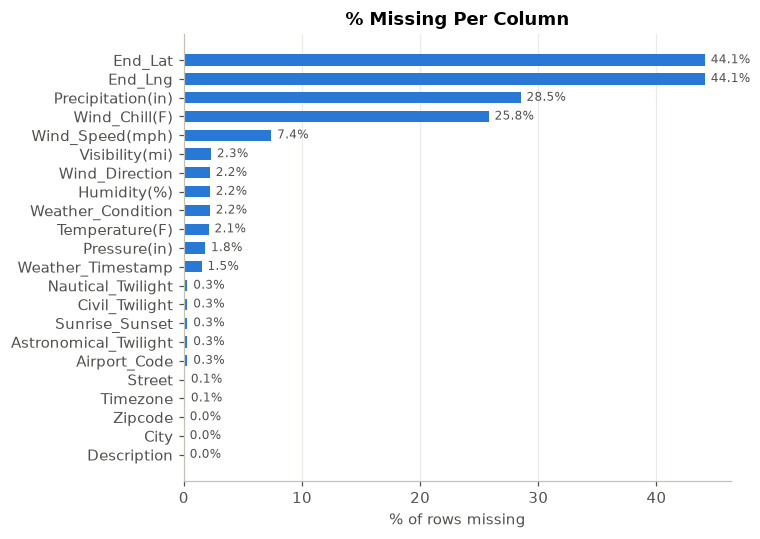

In [30]:
missing = (raw.isna().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0].round(1)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(missing.index[::-1], missing.values[::-1], color=BLUE, height=0.6)
for i, v in enumerate(missing.values[::-1]):
    ax.text(v + 0.5, i, f"{v}%", va="center", fontsize=8, color=GRAY)
ax.set_title("% Missing Per Column"); ax.set_xlabel("% of rows missing"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## Distribution of Severity Level

,count,%
Severity,,
1,4274,0.85
2,398142,79.63
3,84520,16.90
4,13064,2.61


High severity (3–4): 19.5%


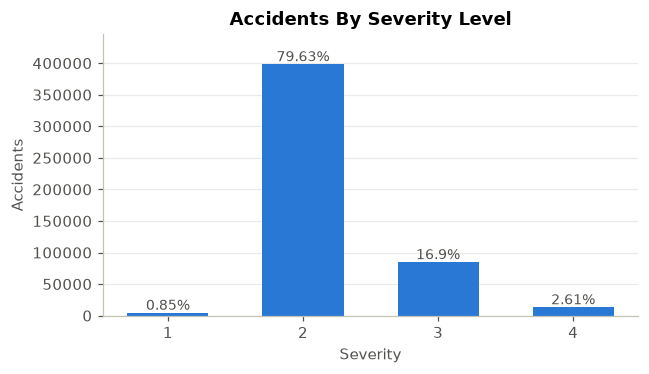

In [31]:
df["High_Sev"] = (df["Severity"] >= 3).astype(int)
sev = df["Severity"].value_counts().sort_index()
sev_pct = (sev / len(df) * 100).round(2)
display(pd.DataFrame({"count": sev, "%": sev_pct}))
print(f"High severity (3–4): {df['High_Sev'].mean()*100:.1f}%")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(sev.index.astype(str), sev.values, color=BLUE, width=0.6)
for x, (c, p) in enumerate(zip(sev.values, sev_pct.values)):
    ax.text(x, c + 5000, f"{p}%", ha="center", fontsize=9, color=GRAY)
ax.set_ylim(0, sev.max() * 1.12)
ax.set_title("Accidents By Severity Level"); ax.set_xlabel("Severity"); ax.set_ylabel("Accidents")
ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

## Important to Note Severity between 2 Sources
Is there a difference between the 2 sources? Any inconsistencies?

In [32]:
print(df["Source"].value_counts())
(pd.crosstab(df["Source"], df["Severity"], normalize="index") * 100).round(1)

Source
Source1    279623
Source2    214044
Source3      6333
Name: count, dtype: int64


Severity,1,2,3,4
Source,,,,
Source1,0.6,91.2,3.8,4.3
Source2,1.0,64.9,33.6,0.4
Source3,4.4,64.7,30.8,0.1


In [34]:
df["Start_Time"] = pd.to_datetime(df["Start_Time"].astype(str).str[:19], errors="coerce")
df["Year"] = df["Start_Time"].dt.year

In [35]:
(pd.crosstab(df["Year"], df["Severity"], normalize="index") * 100).round(1)

Severity,1,2,3,4
Year,,,,
2016,0.1,65.9,30.7,3.3
2017,0.0,64.2,32.4,3.3
2018,0.0,64.4,32.8,2.8
2019,0.0,71.9,25.1,3.0
2020,2.4,79.1,15.8,2.7
2021,0.0,88.6,9.5,1.9
2022,2.1,91.0,4.5,2.4
2023,0.0,97.0,0.0,3.0


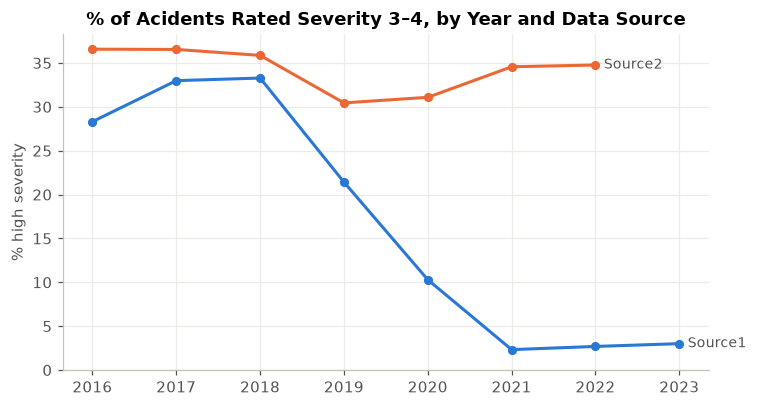

In [37]:
yr = df[df["Source"].isin(["Source1", "Source2"])].groupby(["Year", "Source"])["High_Sev"].mean().unstack() * 100
fig, ax = plt.subplots(figsize=(7, 3.8))
for src, col in [("Source1", BLUE), ("Source2", ORANGE)]:
    s = yr[src].dropna()
    ax.plot(s.index, s.values, color=col, lw=2, marker="o", ms=5)
    ax.text(s.index[-1] + 0.1, s.values[-1], src, color=GRAY, va="center", fontsize=9)
ax.set_title("% of Acidents Rated Severity 3–4, by Year and Data Source")
ax.set_ylabel("% high severity"); ax.set_ylim(0, None); plt.tight_layout(); plt.show()

## Numeric Columns and Outliers

In [38]:
num_cols = ["Temperature(F)", "Wind_Chill(F)", "Humidity(%)", "Pressure(in)",
            "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)", "Distance(mi)"]
df[num_cols].describe(percentiles=[.01, .5, .99]).T.round(2)

,count,mean,std,min,1%,50%,99%,max
Temperature(F),489534.0,61.65,19.00,-77.80,12.00,64.00,96.00,207.00
Wind_Chill(F),370983.0,58.23,22.35,-53.20,-2.00,62.00,95.00,207.00
Humidity(%),488870.0,64.83,22.83,1.00,12.00,67.00,100.00,100.00
Pressure(in),491072.0,29.54,1.01,0.12,24.56,29.86,30.44,38.44
Visibility(mi),488709.0,9.09,2.71,0.00,0.50,10.00,10.00,130.00
Wind_Speed(mph),463013.0,7.68,5.43,0.00,0.00,7.00,23.00,822.80
Precipitation(in),357384.0,0.01,0.10,0.00,0.00,0.00,0.18,10.13
Distance(mi),500000.0,0.56,1.77,0.00,0.00,0.03,7.01,193.48


In [39]:
# Reasonable ranges to determine and filter for outliers in the numeric columns
valid_range = {
    "Temperature(F)": (-40, 130), "Wind_Chill(F)": (-60, 130), "Humidity(%)": (0, 100),
    "Pressure(in)": (20, 32), "Visibility(mi)": (0, 50), "Wind_Speed(mph)": (0, 100),
    "Precipitation(in)": (0, 5),
}
out = pd.DataFrame({c: {"below_min": (df[c] < lo).sum(), "above_max": (df[c] > hi).sum(),
                        "range_used": f"{lo} to {hi}"} for c, (lo, hi) in valid_range.items()}).T
out

,below_min,above_max,range_used
Temperature(F),1,3,-40 to 130
Wind_Chill(F),0,3,-60 to 130
Humidity(%),0,0,0 to 100
Pressure(in),23,1,20 to 32
Visibility(mi),0,74,0 to 50
Wind_Speed(mph),0,7,0 to 100
Precipitation(in),0,29,0 to 5
